# 03 Data Pipeline

- Sanity checks for the newly built `landslide_analysis.data.Landslide4SenseDataset`, loaded with PyTorch.
- Serves the splits from `splits.json` normalized with
`normalisation_stats.json` (both produced by notebook 02).

#### Build the three splits

Sizes must match the 70/15/15 split of the 3799 labelled images.

In [1]:
from pathlib import Path

from landslide_analysis import Landslide4SenseDataset, get_data_dir

data_dir = get_data_dir()

datasets = {
    split: Landslide4SenseDataset(data_dir, split, "splits.json", "normalisation_stats.json")
    for split in ["train", "val", "test"]
}

for split, ds in datasets.items():
    image, mask = ds[0]
    print(f"{split:5s} n={len(ds):4d}  image {tuple(image.shape)} {image.dtype}  mask {tuple(mask.shape)} {mask.dtype}")

assert sum(len(ds) for ds in datasets.values()) == 3799

train n=2659  image (14, 128, 128) torch.float32  mask (128, 128) torch.float32
val   n= 570  image (14, 128, 128) torch.float32  mask (128, 128) torch.float32
test  n= 570  image (14, 128, 128) torch.float32  mask (128, 128) torch.float32


#### Check the normalization

Per-band mean/std over the whole train split should come out 0/1

In [2]:
import torch
from torch.utils.data import DataLoader

loader = DataLoader(datasets["train"], batch_size=64)

n_bands = 14
total = torch.zeros(n_bands)
total_sq = torch.zeros(n_bands)
n_pixels = 0

for images, _ in loader:
    total += images.sum(dim=(0, 2, 3))
    total_sq += (images**2).sum(dim=(0, 2, 3))
    n_pixels += images.shape[0] * images.shape[2] * images.shape[3]

mean = total / n_pixels
std = (total_sq / n_pixels - mean**2).sqrt()

for band in range(n_bands):
    print(f"Band {band + 1:2d}: mean={mean[band]:8.4f}  std={std[band]:7.4f}")

assert mean.abs().max() < 0.01 and (std - 1).abs().max() < 0.01

Band  1: mean= -0.0000  std= 1.0000
Band  2: mean= -0.0000  std= 1.0000
Band  3: mean=  0.0000  std= 1.0000
Band  4: mean= -0.0000  std= 1.0000
Band  5: mean= -0.0000  std= 1.0000
Band  6: mean=  0.0000  std= 1.0000
Band  7: mean= -0.0000  std= 1.0000
Band  8: mean=  0.0000  std= 1.0000
Band  9: mean=  0.0000  std= 1.0000
Band 10: mean= -0.0000  std= 1.0000
Band 11: mean= -0.0000  std= 1.0000
Band 12: mean=  0.0000  std= 1.0000
Band 13: mean=  0.0000  std= 1.0000
Band 14: mean=  0.0000  std= 1.0000


#### Visual check: image and mask still line up

RGB composite (bands 4, 3, 2) next to its mask.

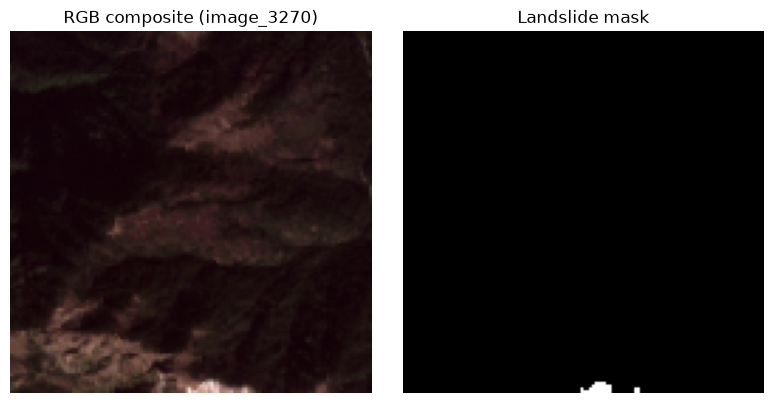

In [3]:
import matplotlib.pyplot as plt

ds = datasets["train"]
index = next(i for i in range(len(ds)) if ds[i][1].sum() > 0)  # a sample with a landslide
image, mask = ds[index]

rgb = image[[3, 2, 1]].permute(1, 2, 0)
rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min())

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(rgb)
axes[0].set_title(f"RGB composite (image_{ds.ids[index]})")
axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Landslide mask")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

#### Batching works

One shuffled batch, as the training will consume it.

In [4]:
loader = DataLoader(datasets["train"], batch_size=8, shuffle=True)
images, masks = next(iter(loader))
print("images:", tuple(images.shape), images.dtype)
print("masks: ", tuple(masks.shape), masks.dtype)

images: (8, 14, 128, 128) torch.float32
masks:  (8, 128, 128) torch.float32
